# 02 · The fix: teach the 2.6 MB tagger what real names look like

**Katip lab, notebook 2 of 3.** Quick mode ~25 minutes, full mode ~1.5 hours (laptop CPU).

### Hypothesis

The tiny tagger fails on real text because its training data is narrow (8,000 templated documents),
**not** because 2.5 million parameters are too few. So: keep the architecture, size, tokenizer
recipe and training recipe of `ml/train.py` exactly as they are, and change **one thing**, the
data, by mixing in *N* real sentences from Wiki NER train.

### Design (one variable)

* *N* (real sentences) ∈ {0, 500, 2,000, 8,000, 17,967}. *N = 0* re-trains today's model, so the
  baseline goes through the same code.
* 3 seeds per *N*, so we can tell an effect from training noise.
* Every choice is made on **Wiki NER dev** (real) and Katip's **held-out** set (synthetic, already a
  dev set). Wiki NER test, the blind set and the name-free set stay sealed until notebook 3.

A second knob comes for free: the pipeline's **trust** setting. A model name scored at or above
`trust` skips the "two capitalised words" rule. Today that rule is what protects precision; a model
that has seen real text may not need it as much. We try `trust` ∈ {off, 0.9, 0.8, 0.7, 0.6, 0.5}.

In [1]:
import json, time, random
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
import katiplab as K

QUICK = True     # True: N in {0, 2000, 17967} and 1 seed (~25 min). False: the full grid (~1.5 h).

GRID = [0, 2000, 17967] if QUICK else [0, 500, 2000, 8000, 17967]
SEEDS = [0] if QUICK else [0, 1, 2]
print(f"{len(GRID) * len(SEEDS)} training runs: N={GRID}, seeds={SEEDS}")

3 training runs: N=[0, 2000, 17967], seeds=[0]


## 2.1 · Pre-registration

Scientists write down what would count as success **before** they see the result, so they can't
move the goalposts afterwards. Run this cell once, before training. It refuses to overwrite an
existing file.

| | hypothesis | pass if (on the sealed test, notebook 3) |
| --- | --- | --- |
| H1 | real text helps | Tiny **pipeline** name recall on Wiki NER test improves by **≥ 15 points**, McNemar p < 0.05 |
| H2 | nothing breaks | blind-set name recall of the pipeline stays **≥ 99.0%** (today: 99.7%) |
| H3 | no new false alarms on legal prose | false names on the name-free set stay **≤ 5** (today: 3) |
| H4 | still tiny | int8 model **≤ 3.0 MB** |

Selection rule (decided now): among (*N*, trust) settings whose held-out name recall is **≥ 96.5%**
(published Tiny: 97.5%), pick the best **mean Wiki NER dev F2**; ties within 0.5 points go to the
smaller *N*, then the stricter trust. F2 is the F-score that weighs recall twice as much as
precision: for redaction a missed name is a leak, an extra highlight is a click.

In [2]:
prereg = K.RESULTS / "02_prereg.json"
if not prereg.exists():
    prereg.write_text(json.dumps({
        "written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "H1": "Wiki NER test, Tiny pipeline name recall: +15 points or more vs published Tiny, McNemar p < 0.05",
        "H2": "blind set pipeline name recall >= 0.990",
        "H3": "negatives (name-free legal prose): false names <= 5",
        "H4": "int8 ONNX <= 3.0 MB",
        "selection": "heldout recall >= 0.965; best mean Wiki dev F2 over N x trust {None,.9,.8,.7,.6,.5}; ties within 0.005 -> smaller N, then stricter trust",
        "grid": GRID, "seeds": SEEDS,
    }, indent=1))
print(prereg.read_text())

{
 "written_utc": "2026-11-12T01:38:33+00:00",
 "H1": "Wiki NER test, Tiny pipeline name recall: +15 points or more vs published Tiny, McNemar p < 0.05",
 "H2": "blind set pipeline name recall >= 0.990",
 "H3": "negatives (name-free legal prose): false names <= 5",
 "H4": "int8 ONNX <= 3.0 MB",
 "selection": "heldout recall >= 0.965; best mean Wiki dev F2 over N x trust {None,.9,.8,.7,.6,.5}; ties within 0.005 -> smaller N, then stricter trust",
 "grid": [
  0,
  2000,
  17967
 ],
 "seeds": [
  0
 ]
}


## 2.2 · Train

Runs are resumable: a finished run (folder with `train_info.json`) is skipped, so you can stop the
kernel and continue later. Each run prints its loss per epoch; expect 5–8 minutes per run.

Real sentences are packed 8 at a time into pseudo-documents so they look like Katip's documents to
the trainer (`K.pack`). For each seed, the *N* sentences are the first *N* of a seeded shuffle, so
a larger *N* always contains the smaller ones.

In [3]:
wiki_train = K.load_wiki("train")
synth_train = K.load_synth("train")

def run_dir(n, seed): return K.RUNS / f"tiny_real{n}_seed{seed}"

t_start = time.time()
for seed in SEEDS:
    shuffled = wiki_train[:]; random.Random(seed).shuffle(shuffled)
    for n in GRID:
        out = run_dir(n, seed)
        if (out / "train_info.json").exists():
            print("done already:", out.name); continue
        print(f"--- {out.name}")
        K.train_tiny(out, real_docs=K.pack(shuffled[:n]), synth_docs=synth_train, seed=seed)
print(f"all runs finished in {(time.time() - t_start) / 60:.0f} min")

--- tiny_real0_seed0


/Users/f1k0/Development/Personal/Projects/active/katip/ml/berturk/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 02:38:38.787000 45290 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.





8000 docs (0 real) · 8240 sequences · 2,478,211 params · 1290 steps
  epoch 1/5  loss 0.0569  (22s)
  epoch 2/5  loss 0.0397  (44s)
  epoch 3/5  loss 0.0434  (66s)
  epoch 4/5  loss 0.0320  (88s)
  epoch 5/5  loss 0.0232  (109s)


/Users/f1k0/Development/Personal/Projects/active/katip/ml/berturk/.venv/lib/python3.13/site-packages/transformers/masking_utils.py:208: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
/Users/f1k0/Development/Personal/Projects/active/katip/ml/berturk/.venv/lib/python3.13/site-packages/transformers/integrations/sdpa_attention.py:140: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  is_causal = q_length > 1 and attention_mask is None and is_causal
/Users/f1k0/Development/Personal/Proj

  saved tiny_real0_seed0: int8 2.57 MB, 110 s
--- tiny_real2000_seed0



8250 docs (250 real) · 8614 sequences · 2,478,211 params · 1350 steps
  epoch 1/5  loss 0.0579  (24s)
  epoch 2/5  loss 0.0381  (49s)
  epoch 3/5  loss 0.0337  (72s)
  epoch 4/5  loss 0.0478  (96s)
  epoch 5/5  loss 0.0323  (119s)
  saved tiny_real2000_seed0: int8 2.57 MB, 119 s
--- tiny_real17967_seed0



10246 docs (2246 real) · 10837 sequences · 2,478,211 params · 1695 steps
  epoch 1/5  loss 0.0781  (30s)
  epoch 2/5  loss 0.1053  (60s)
  epoch 3/5  loss 0.0812  (90s)
  epoch 4/5  loss 0.0834  (119s)
  epoch 5/5  loss 0.0748  (149s)
  saved tiny_real17967_seed0: int8 2.57 MB, 149 s
all runs finished in 6 min


## 2.3 · Score every run on dev

For each run: the model alone, and the pipeline at each trust setting. Sets: Wiki NER dev (real)
and held-out (synthetic). About 1 minute per run.

In [4]:
dev_sets = {"wiki dev": K.load_wiki("dev"), "heldout": K.load_synth("heldout")}
TRUSTS = [None, 0.9, 0.8, 0.7, 0.6, 0.5]
rows = []
for seed in SEEDS:
    for n in GRID:
        tg = K.Tagger(run_dir(n, seed))
        uses = [("model only", None, K.model_only(tg))] + [("pipeline", t, K.pipeline(tg, trust=t)) for t in TRUSTS]
        for use, trust, det in uses:
            res = K.evaluate(use, det, dev_sets)
            rows.append({"N": n, "seed": seed, "use": use, "trust": "off" if trust is None else trust, "MB": round(tg.size_mb, 2),
                         **{f"{s} {m}": res[s][m] for s in dev_sets for m in ("recall", "precision", "f2", "false")}})
        print("scored", run_dir(n, seed).name)
df = pd.DataFrame(rows)
df.to_csv(K.RESULTS / "02_dev_scores.csv", index=False)

scored tiny_real0_seed0
scored tiny_real2000_seed0
scored tiny_real17967_seed0


In [5]:
show = ["wiki dev recall", "wiki dev precision", "wiki dev f2", "heldout recall", "MB"]
agg = df.groupby(["use", "trust", "N"])[show].mean()
agg.round(3)

wiki dev recall  wiki dev precision  wiki dev f2  \
use        trust N                                                         
model only off   0                0.253               0.141        0.218   
                 2000             0.285               0.406        0.304   
                 17967            0.451               0.595        0.474   
pipeline   0.5   0                0.298               0.246        0.286   
                 2000             0.348               0.401        0.357   
                 17967            0.516               0.559        0.524   
           0.6   0                0.262               0.251        0.260   
                 2000             0.270               0.429        0.291   
                 17967            0.406               0.592        0.433   
           0.7   0                0.237               0.258        0.241   
                 2000             0.209               0.426        0.233   
                 17967            0.321               0.595        0.354   
           0.8   0                0.197               0.257        0.206   
                 2000             0.168               0.449        0.193   
                 17967            0.226               0.588        0.258   
           0.9   0                0.167               0.304        0.183   
                 2000             0.137               0.479        0.160   
                 17967            0.176               0.595        0.205   
           off   0                0.106               0.526        0.126   
                 2000             0.108               0.533        0.128   
                 17967            0.126               0.546        0.149   

                        heldout recall    MB  
use        trust N                            
model only off   0               0.971  2.57  
                 2000            0.971  2.57  
                 17967           0.989  2.57  
pipeline   0.5   0               0.993  2.57  
                 2000            0.993  2.57  
                 17967           1.000  2.57  
           0.6   0               0.993  2.57  
                 2000            0.993  2.57  
                 17967           0.993  2.57  
           0.7   0               0.993  2.57  
                 2000            0.993  2.57  
                 17967           0.993  2.57  
           0.8   0               0.993  2.57  
                 2000            0.993  2.57  
                 17967           0.993  2.57  
           0.9   0               0.993  2.57  
                 2000            0.993  2.57  
                 17967           0.993  2.57  
           off   0               0.978  2.57  
                 2000            0.975  2.57  
                 17967           0.971  2.57

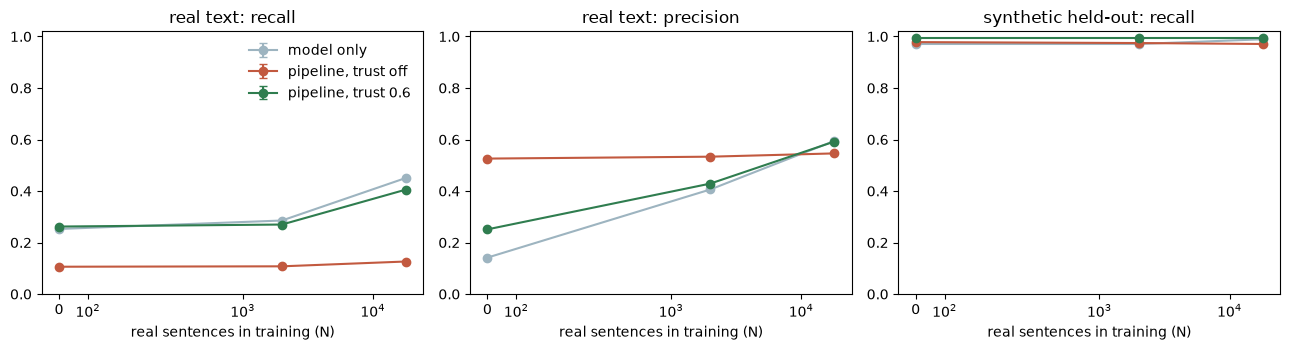

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
curves = [("model only", "off", "#9db4c0", "model only"), ("pipeline", "off", "#c2593f", "pipeline, trust off"),
          ("pipeline", 0.6, "#2f7d4f", "pipeline, trust 0.6")]
for use, trust, color, label in curves:
    g = df[(df.use == use) & (df.trust == trust)].groupby("N")
    for ax, col, title in zip(axes, ["wiki dev recall", "wiki dev precision", "heldout recall"],
                              ["real text: recall", "real text: precision", "synthetic held-out: recall"]):
        m, s = g[col].mean(), g[col].std().fillna(0)
        ax.errorbar(m.index, m.values, yerr=s.values, marker="o", capsize=3, label=label, color=color)
        ax.set_title(title); ax.set_xscale("symlog", linthresh=500); ax.set_ylim(0, 1.02); ax.set_xlabel("real sentences in training (N)")
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

**How to read the curves.**

* *Left*: if the hypothesis is right, real-text recall climbs with *N* and flattens. Where it
  flattens tells you how much labelled real data a tiny model can use, which is a result in itself.
* *Middle*: precision on real text should climb too: real negatives teach the model that most
  capitalised words in prose are not names.
* *Green vs red*: with a model that has seen real text, trusting its confident names should add
  real names without the flood of false ones that the published model produces at low trust.
* *Right*: the synthetic score must stay flat near the top. If it drops, the model is trading the
  legal templates for Wikipedia, and you need more synthetic weight.

## 2.4 · Select (by the pre-registered rule)

In [7]:
cand = df[df.use == "pipeline"].groupby(["N", "trust"])[["wiki dev f2", "heldout recall"]].mean().reset_index()
cand = cand[cand["heldout recall"] >= 0.965]
best = cand["wiki dev f2"].max()
ok = cand[cand["wiki dev f2"] >= best - 0.005].copy()
ok["strict"] = ok.trust.map(lambda t: 0 if t == "off" else -float(t))   # off is strictest, then 0.9, 0.8 ...
choice = ok.sort_values(["N", "strict"]).iloc[0]
selected = {"N": int(choice.N), "trust": None if choice.trust == "off" else float(choice.trust),
            "dev_f2": round(float(choice["wiki dev f2"]), 4), "heldout_recall": round(float(choice["heldout recall"]), 4),
            "seeds": SEEDS, "model_dirs": [str(run_dir(int(choice.N), s).relative_to(K.ROOT)) for s in SEEDS]}
(K.RESULTS / "02_selected.json").write_text(json.dumps(selected, indent=1))
selected

{'N': 17967,
 'trust': 0.5,
 'dev_f2': 0.5243,
 'heldout_recall': 1.0,
 'seeds': [0],
 'model_dirs': ['lab/runs/tiny_real17967_seed0']}

If the chosen trust sits at the edge of the grid (0.5), lower values might be better still. Do not
change this run: write a new pre-registration with a wider grid and test it on fresh data, or report
the edge as a limitation.

## Conclusion you should be able to state

> With the same 2.5 M-parameter, 2.6 MB tagger and the same training recipe, adding *N* real
> sentences (and trust T) raised real-text name recall from X to Y on dev, while the held-out set
> stayed at Z.

Notebook 3 opens the sealed test set once, checks the four pre-registered hypotheses and writes the
report.